# Member C: ResNet34 + Grad-CAM (brain tumour MRI, 4 classes)

Classes: `glioma`, `meningioma`, `notumor`, `pituitary`.

**What this notebook does**

1. Verifies `shared/split.csv` (counts, labels, leakage, image paths). The split is **not** modified.
2. Trains ImageNet-pretrained ResNet34 (final layer replaced with 4 outputs) under three preprocessing conditions:
   `baseline`, `fixed` (Member B's `fixed_preprocess`), `adaptive` (Member B's `adaptive_preprocess`).
   Model selection uses **validation** macro F1 only.
3. Evaluates the test set once, for the final comparison table.
4. Saves the selected checkpoint to `models/resnet34_brain_tumor_best.pth`.
5. Exports `shared/preds_resnet.csv` (test) and `shared/val_probs_resnet.csv` (validation).
6. Generates Grad-CAM examples under `outputs/gradcam/`.
7. Ends with a **LIVE DEMONSTRATION** cell that loads the checkpoint without retraining.

> **Grad-CAM is an approximate visual explanation of what the network attended to. It is not tumour segmentation.**
> Heatmaps can highlight regions that are not tumour, and they can miss parts of a tumour.

**Running it:** open this notebook from the `Brain_Tumour_Project` folder. Place the images so that the paths in
`shared/split.csv` resolve under `datasets/` (for example `datasets/Training/glioma/Tr-gl_1.jpg`). The first run
downloads the ImageNet ResNet34 weights through torchvision. A GPU is strongly recommended; the notebook also runs on CPU, but slowly.

In [9]:
import sys
print(sys.executable)

C:\Python313\python.exe


## 1. Setup and reproducibility

In [10]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader


def find_root():
    """Find the project root (the folder that contains common/ and shared/)."""
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / "common" / "preprocess.py").exists() and (p / "shared" / "split.csv").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the Brain_Tumour_Project folder.")


ROOT = find_root()
sys.path.insert(0, str(ROOT))

from common import resnet_gradcam as rg            # Member C helpers
from common.preprocess import DEFAULT_THRESHOLDS   # Member B's thresholds (shared with 03 notebook)

SEED = 42
rg.set_seed(SEED)
DEVICE = rg.get_device()

DATA_DIR = ROOT / "datasets"          # <- change if your images live elsewhere
SPLIT_CSV = ROOT / "shared" / "split.csv"
SHARED_DIR = ROOT / "shared"
OUT_DIR = ROOT / "outputs" / "resnet34"
GRADCAM_DIR = ROOT / "outputs" / "gradcam"
MODEL_PATH = ROOT / "models" / "resnet34_brain_tumor_best.pth"
for d in [OUT_DIR, GRADCAM_DIR, MODEL_PATH.parent]:
    d.mkdir(parents=True, exist_ok=True)

print("Project root :", ROOT)
print("Device       :", DEVICE, "| torch", torch.__version__)
print("Thresholds   :", DEFAULT_THRESHOLDS)

Project root : C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project
Device       : cpu | torch 2.14.1+cpu
Thresholds   : {'contrast_threshold': 0.13575222715735435, 'noise_threshold': 0.0018169281538575888, 'sharpness_threshold': 0.0005936163215665147}


## 2. Verify the data split (no modification)

In [11]:
SMOKE_TEST = False   # True = tiny end-to-end pipeline check (1 epoch, few images). Keep False for real results.

df_all = rg.load_split(SPLIT_CSV, DATA_DIR,
                       verify_paths=True,
                       check_counts=not SMOKE_TEST)   # raises on wrong counts, bad labels, leakage, missing images

print("Rows per split:")
display(df_all["split"].value_counts().reindex(["train", "val", "test"]).to_frame("images"))
print("Rows per split and class:")
display(pd.crosstab(df_all["split"], df_all["label"]))

train_df = df_all[df_all["split"] == "train"].reset_index(drop=True)
val_df = df_all[df_all["split"] == "val"].reset_index(drop=True)
test_df = df_all[df_all["split"] == "test"].reset_index(drop=True)

# Explicit leakage checks (load_split also checks duplicates)
assert set(train_df["filename"]).isdisjoint(val_df["filename"]), "train/val leakage"
assert set(train_df["filename"]).isdisjoint(test_df["filename"]), "train/test leakage"
assert set(val_df["filename"]).isdisjoint(test_df["filename"]), "val/test leakage"
print("Leakage checks passed. All image paths resolved.")

Rows per split:


,images
split,
train,4361
val,754
test,1598


Rows per split and class:


label,glioma,meningioma,notumor,pituitary
split,,,,
test,399,399,400,400
train,1177,1112,869,1203
val,219,181,159,195


Leakage checks passed. All image paths resolved.


## 3. Configuration and (optional) smoke-test subset

In [12]:

# ============================================================
# SECTION 3: CONFIGURATION AND REDUCED TRAINING SUBSET
# ============================================================

import pandas as pd
import torch

# Reduced settings for a CPU development run
EPOCHS = 3
BATCH_SIZE = 8
LR = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 2
NUM_WORKERS = 0
PRETRAINED = True
THRESHOLDS = DEFAULT_THRESHOLDS

# Keep the existing reproducible seed
SEED = 42
rg.set_seed(SEED)

# Keep the original validation and test sets unchanged.
# Reduce only the training set, proportionally across labels.
TRAIN_FRACTION = 0.20

print("Original training size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

train_df = (
    train_df.groupby("label", group_keys=False)
    .sample(frac=TRAIN_FRACTION, random_state=SEED)
    .reset_index(drop=True)
)

print("\nReduced training size:", len(train_df))
print("\nTraining images per class:")
print(train_df["label"].value_counts())

print("\nFinal configuration")
print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Pretrained weights:", PRETRAINED)
print("DataLoader workers:", NUM_WORKERS)
print("Training fraction:", TRAIN_FRACTION)

assert len(train_df) > 0
assert set(train_df["filename"]).isdisjoint(val_df["filename"])
assert set(train_df["filename"]).isdisjoint(test_df["filename"])
assert set(val_df["filename"]).isdisjoint(test_df["filename"])

print("\nConfiguration ready.")


Original training size: 4361
Validation size: 754
Test size: 1598

Reduced training size: 872

Training images per class:
label
pituitary     241
glioma        235
meningioma    222
notumor       174
Name: count, dtype: int64

Final configuration
Device: cpu
Epochs: 3
Batch size: 8
Pretrained weights: True
DataLoader workers: 0
Training fraction: 0.2

Configuration ready.


In [14]:
import inspect

print(inspect.getsource(rg.train_with_early_stopping))

def train_with_early_stopping(model, train_loader, val_loader, device,
                              epochs=15, lr=1e-4, weight_decay=1e-4,
                              patience=5, log_fn=print):
    """Fine-tune all layers; select the epoch with the best validation macro F1.

    Returns (best_model_on_cpu_state_loaded, history_df, best_epoch).
    Only validation data influences model selection.
    """
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history, best_f1, best_epoch, best_state, bad = [], -1.0, -1, None, 0
    for epoch in range(1, epochs + 1):
        tr = _run_epoch(model, train_loader, criterion, device, optimizer)
        va = _run_epoch(model, val_loader, criterion, device, None)
        scheduler.step()
        history.append({"epoch": epoch, "lr": optimizer.param_groups[0]["lr"]

In [15]:
print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(make_loaders("baseline")[0]))

Device: cpu
Epochs: 3
Batch size: 8
Training batches: 109


In [16]:
import inspect

print(inspect.getsource(rg._run_epoch))

def _run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, ys, ps = 0.0, [], []
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for x, y, _ in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            ys.append(y.cpu().numpy())
            ps.append(logits.argmax(1).cpu().numpy())
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(ps)
    m = compute_metrics(y_true, y_pred)
    return {"loss": total_loss / len(y_true), **m}



In [17]:

import copy
import numpy as np
import pandas as pd
import torch
from torch import nn

def _run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    ys, ps = [], []
    total_batches = len(loader)
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch_idx, (x, y, _) in enumerate(loader, start=1):
            x, y = x.to(device), y.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            ys.append(y.detach().cpu().numpy())
            ps.append(logits.detach().argmax(1).cpu().numpy())

            if batch_idx % 10 == 0 or batch_idx == total_batches:
                phase = "Train" if training else "Validation"
                print(
                    f"{phase}: {batch_idx}/{total_batches} batches "
                    f"({100 * batch_idx / total_batches:.1f}%)",
                    flush=True
                )

    y_true = np.concatenate(ys)
    y_pred = np.concatenate(ps)
    metrics = compute_metrics(y_true, y_pred)

    return {"loss": total_loss / len(y_true), **metrics}


def train_with_early_stopping(
    model, train_loader, val_loader, device,
    epochs=3, lr=1e-4, weight_decay=1e-4,
    patience=2, log_fn=print
):
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )

    history = []
    best_f1, best_epoch = -1.0, -1
    best_state = None
    bad = 0

    for epoch in range(1, epochs + 1):
        log_fn(f"\n===== EPOCH {epoch}/{epochs} — TRAINING =====")
        train_metrics = _run_epoch(
            model, train_loader, criterion, device, optimizer
        )

        log_fn(f"\n===== EPOCH {epoch}/{epochs} — VALIDATION =====")
        val_metrics = _run_epoch(
            model, val_loader, criterion, device
        )

        scheduler.step()

        history.append({
            "epoch": epoch,
            "lr": optimizer.param_groups[0]["lr"],
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()}
        })

        log_fn(
            f"Epoch {epoch}: "
            f"train loss={train_metrics['loss']:.4f}, "
            f"accuracy={train_metrics['accuracy']:.4f}, "
            f"macro F1={train_metrics['macro_f1']:.4f} | "
            f"val loss={val_metrics['loss']:.4f}, "
            f"accuracy={val_metrics['accuracy']:.4f}, "
            f"macro F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            best_state = copy.deepcopy({
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            })
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                log_fn(f"Early stopping. Best epoch: {best_epoch}")
                break

    if best_state is None:
        raise RuntimeError("Training did not produce a valid model checkpoint.")

    model.load_state_dict(best_state)

    return model, pd.DataFrame(history), best_epoch


# Confirm the replacement is active
print("Updated training functions successfully!")
print("Device:", DEVICE)
print("Epochs for the initial test: 1")


Updated training functions successfully!
Device: cpu
Epochs for the initial test: 1


In [19]:

# ============================================================
# FIX: CONNECT THE METRICS FUNCTION TO THE TRAINING HELPER
# ============================================================

def _run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    ys, ps = [], []
    total_batches = len(loader)
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch_idx, (x, y, _) in enumerate(loader, start=1):
            x, y = x.to(device), y.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            ys.append(y.detach().cpu().numpy())
            ps.append(logits.detach().argmax(1).cpu().numpy())

            if batch_idx % 10 == 0 or batch_idx == total_batches:
                phase = "Train" if training else "Validation"
                print(
                    f"{phase}: {batch_idx}/{total_batches} batches "
                    f"({100 * batch_idx / total_batches:.1f}%)",
                    flush=True
                )

    y_true = np.concatenate(ys)
    y_pred = np.concatenate(ps)

    # Use the metric function from your project module
    metrics = rg.compute_metrics(y_true, y_pred)

    return {"loss": total_loss / len(y_true), **metrics}


print("Fixed _run_epoch to use rg.compute_metrics.")


Fixed _run_epoch to use rg.compute_metrics.


## 4. Train the three preprocessing conditions

All three use the same architecture, split, seed, optimiser, schedule and augmentation. Only the preprocessing differs.
Validation macro F1 selects the best epoch within each run.

In [20]:

# ============================================================
# SECTION 4: TRAIN THREE PREPROCESSING CONDITIONS
# CPU-FRIENDLY TEST RUN
# ============================================================

def make_loaders(mode):
    g = torch.Generator()
    g.manual_seed(SEED)

    tr = DataLoader(
        rg.MRIDataset(
            train_df, mode, THRESHOLDS,
            augment=True, seed=SEED
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        generator=g
    )

    va = DataLoader(
        rg.MRIDataset(
            val_df, mode, THRESHOLDS,
            augment=False
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    te = DataLoader(
        rg.MRIDataset(
            test_df, mode, THRESHOLDS,
            augment=False
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    return tr, va, te


# Test settings: one epoch for each preprocessing mode
TEST_EPOCHS = 1
trained = {}

# Create output directory if it doesn't already exist
OUT_DIR.mkdir(parents=True, exist_ok=True)

for mode in rg.PREPROCESS_MODES:
    print(f"\n{'=' * 55}", flush=True)
    print(f"PREPROCESSING MODE: {mode.upper()}", flush=True)
    print(f"{'=' * 55}", flush=True)

    # 1. Build model
    print("Building ResNet34...", flush=True)
    rg.set_seed(SEED)
    model = rg.build_resnet34(pretrained=PRETRAINED)

    # 2. Create data loaders
    print("Creating data loaders...", flush=True)
    tr_dl, va_dl, te_dl = make_loaders(mode)

    print("Training batches:", len(tr_dl), flush=True)
    print("Validation batches:", len(va_dl), flush=True)

    # 3. Check one batch
    print("Checking first training batch...", flush=True)
    batch = next(iter(tr_dl))
    print("Image shape:", tuple(batch[0].shape), flush=True)
    print("Label shape:", tuple(batch[1].shape), flush=True)
    del batch

    # 4. Train using the updated function
    print("Starting training...", flush=True)
    t0 = time.time()

    model, hist, best_ep = train_with_early_stopping(
        model,
        tr_dl,
        va_dl,
        DEVICE,
        epochs=TEST_EPOCHS,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        patience=1
    )

    # 5. Save history and model checkpoint
    history_path = OUT_DIR / f"training_history_{mode}.csv"
    model_path = OUT_DIR / f"resnet34_{mode}_test.pth"

    hist.to_csv(history_path, index=False)
    torch.save(model.state_dict(), model_path)

    print("Saved training history:", history_path, flush=True)
    print("Saved model weights:", model_path, flush=True)

    # 6. Evaluate validation set
    print("Evaluating validation set...", flush=True)

    v_logits, v_probs, v_y, v_idx = rg.predict_loader(
        model, va_dl, DEVICE
    )

    v_metrics = rg.compute_metrics(v_y, v_probs.argmax(1))

    # 7. Store results for later notebook sections
    trained[mode] = {
        "model": model,
        "history": hist,
        "best_epoch": best_ep,
        "val_metrics": v_metrics,
        "val_logits": v_logits,
        "val_probs": v_probs,
        "val_y": v_y,
        "val_idx": v_idx
    }

    print(f"\nCompleted: {mode}", flush=True)
    print("Best epoch:", best_ep, flush=True)
    print(
        f"Validation macro F1: {v_metrics['macro_f1']:.4f}",
        flush=True
    )
    print(
        f"Elapsed time: {(time.time() - t0) / 60:.1f} minutes",
        flush=True
    )

print("\nAll three test runs completed.", flush=True)



PREPROCESSING MODE: BASELINE
Building ResNet34...
Creating data loaders...
Training batches: 109
Validation batches: 95
Checking first training batch...
Image shape: (8, 3, 224, 224)
Label shape: (8,)
Starting training...

===== EPOCH 1/1 — TRAINING =====
Train: 10/109 batches (9.2%)
Train: 20/109 batches (18.3%)
Train: 30/109 batches (27.5%)
Train: 40/109 batches (36.7%)
Train: 50/109 batches (45.9%)
Train: 60/109 batches (55.0%)
Train: 70/109 batches (64.2%)
Train: 80/109 batches (73.4%)
Train: 90/109 batches (82.6%)
Train: 100/109 batches (91.7%)
Train: 109/109 batches (100.0%)

===== EPOCH 1/1 — VALIDATION =====
Validation: 10/95 batches (10.5%)
Validation: 20/95 batches (21.1%)
Validation: 30/95 batches (31.6%)
Validation: 40/95 batches (42.1%)
Validation: 50/95 batches (52.6%)
Validation: 60/95 batches (63.2%)
Validation: 70/95 batches (73.7%)
Validation: 80/95 batches (84.2%)
Validation: 90/95 batches (94.7%)
Validation: 95/95 batches (100.0%)
Epoch 1: train loss=0.5701, accura

In [21]:

import time
import torch

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

# Reuse the baseline model and training loader if available
model = rg.build_resnet34(pretrained=PRETRAINED).to(DEVICE)
tr_dl, va_dl, te_dl = make_loaders("baseline")

batch = next(iter(tr_dl))
images, labels = batch[0], batch[1]

images = images.to(DEVICE)
labels = labels.to(DEVICE)

model.train()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
criterion = torch.nn.CrossEntropyLoss()

start = time.time()
optimizer.zero_grad()
outputs = model(images)
loss = criterion(outputs, labels)
loss.backward()
optimizer.step()

if DEVICE == "cuda":
    torch.cuda.synchronize()

print("Forward + backward completed.")
print("Loss:", loss.item())
print("Time:", round(time.time() - start, 2), "seconds")


Device: cpu
CUDA available: False
Forward + backward completed.
Loss: 1.4955992698669434
Time: 1.83 seconds


### 4a. Training curves

[baseline] columns: ['epoch', 'lr', 'train_loss', 'train_accuracy', 'train_macro_precision', 'train_macro_recall', 'train_macro_f1', 'train_weighted_f1', 'val_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_weighted_f1']


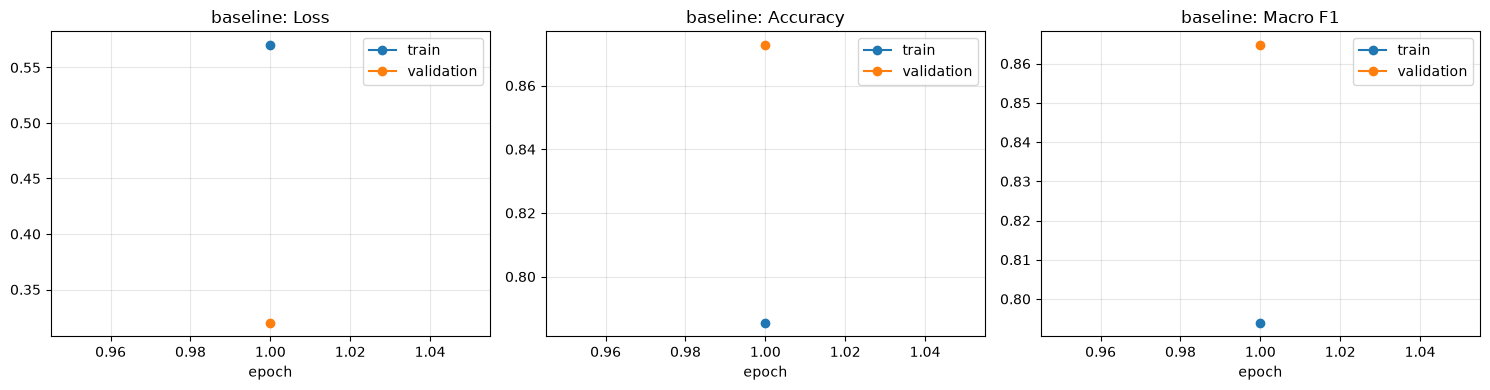

[fixed] columns: ['epoch', 'lr', 'train_loss', 'train_accuracy', 'train_macro_precision', 'train_macro_recall', 'train_macro_f1', 'train_weighted_f1', 'val_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_weighted_f1']


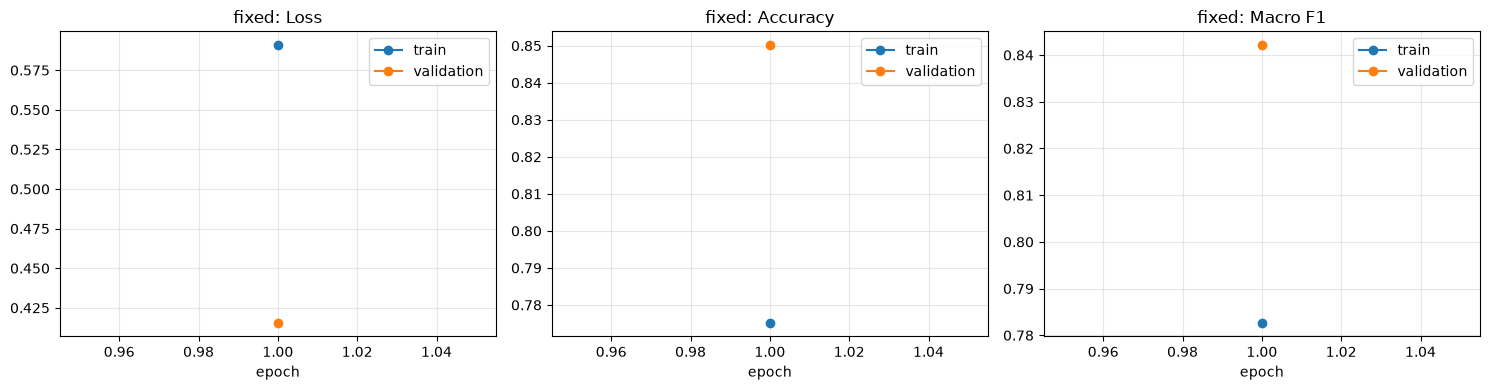

[adaptive] columns: ['epoch', 'lr', 'train_loss', 'train_accuracy', 'train_macro_precision', 'train_macro_recall', 'train_macro_f1', 'train_weighted_f1', 'val_loss', 'val_accuracy', 'val_macro_precision', 'val_macro_recall', 'val_macro_f1', 'val_weighted_f1']


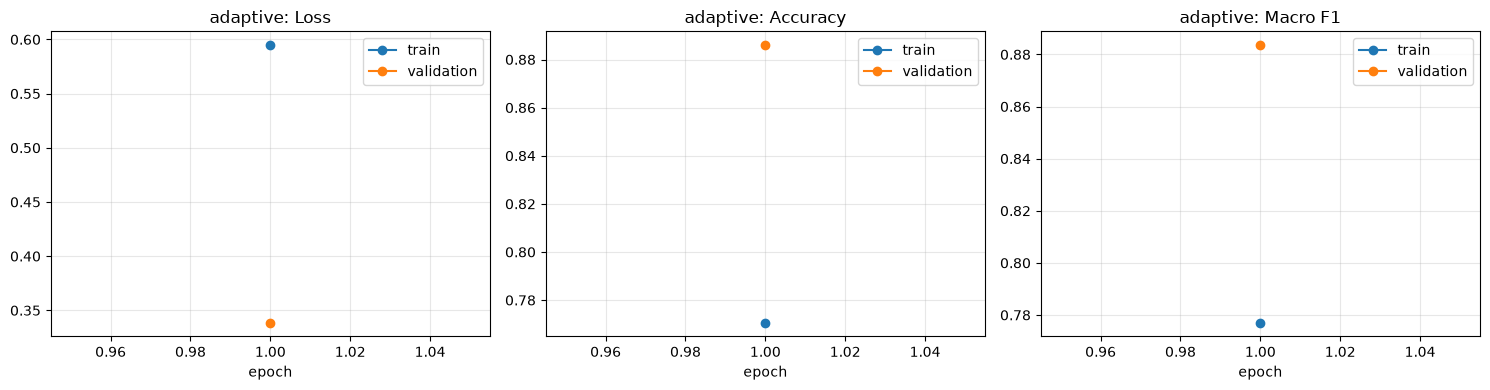

In [22]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

OUT_DIR = Path(OUT_DIR)          # ensure it's a Path
OUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_curves(hist, mode):
    hist = pd.DataFrame(hist)    # works for dict, list of dicts, or DataFrame
    print(f"[{mode}] columns:", list(hist.columns))   # helps debug key names

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, title in zip(axes, ["loss", "accuracy", "macro_f1"],
                                 ["Loss", "Accuracy", "Macro F1"]):
        tr, va = f"train_{metric}", f"val_{metric}"
        missing = [k for k in ("epoch", tr, va) if k not in hist.columns]
        if missing:
            raise KeyError(f"Missing columns {missing}. Available: {list(hist.columns)}")

        ax.plot(hist["epoch"], hist[tr], marker="o", label="train")
        ax.plot(hist["epoch"], hist[va], marker="o", label="validation")
        ax.set_title(f"{mode}: {title}")
        ax.set_xlabel("epoch")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(OUT_DIR / f"training_curves_{mode}.png", dpi=150)
    plt.show()
    plt.close(fig)

for mode in rg.PREPROCESS_MODES:
    plot_curves(trained[mode]["history"], mode)

## 5. Select the model on validation and evaluate the test set once

Selection uses **validation** macro F1 only. The test set is evaluated after selection, for the final comparison table.


Evaluating test set: BASELINE
Test batches: 200
Predictions completed.


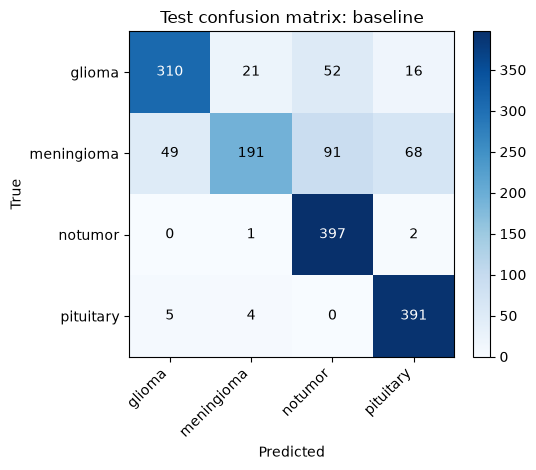

Finished evaluating baseline.

Evaluating test set: FIXED
Test batches: 200
Predictions completed.


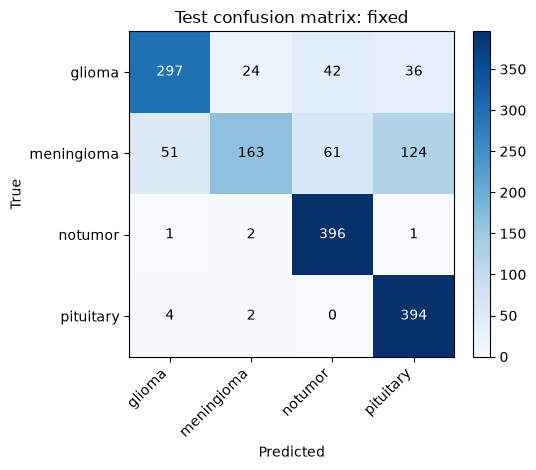

Finished evaluating fixed.

Evaluating test set: ADAPTIVE
Test batches: 200
Predictions completed.


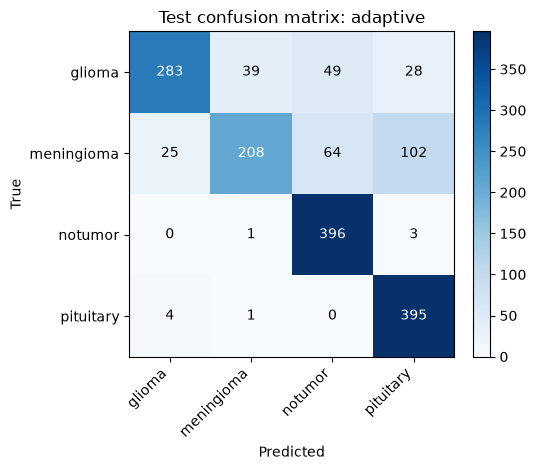

Finished evaluating adaptive.

Validation-based selection (macro F1):
Selected preprocessing: adaptive


,preprocessing,best_epoch,val_accuracy,val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
0,baseline,1,0.8727,0.8647,0.8066,0.8217,0.8064,0.7923,0.7924
1,fixed,1,0.8501,0.8421,0.7822,0.7996,0.7820,0.7621,0.7623
2,adaptive,1,0.8859,0.8835,0.8023,0.8171,0.8020,0.7902,0.7902



All test evaluations completed!


In [24]:

# ============================================================
# SECTION 5: TEST EVALUATION AND COMPARISON
# ============================================================

def plot_cm(cm, title, path):
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(range(len(rg.CLASS_NAMES)))
    ax.set_yticks(range(len(rg.CLASS_NAMES)))
    ax.set_xticklabels(rg.CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticklabels(rg.CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, cm[i, j],
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    plt.close(fig)


test_store = {}
rows = []

for mode in rg.PREPROCESS_MODES:
    print(f"\nEvaluating test set: {mode.upper()}", flush=True)

    _, _, te_dl = make_loaders(mode)
    print(f"Test batches: {len(te_dl)}", flush=True)

    # Predict on the complete test set
    t_logits, t_probs, t_y, t_idx = rg.predict_loader(
        trained[mode]["model"], te_dl, DEVICE
    )

    print("Predictions completed.", flush=True)

    t_pred = t_probs.argmax(1)
    test_store[mode] = {
        "logits": t_logits,
        "probs": t_probs,
        "y": t_y,
        "idx": t_idx
    }

    tm = rg.compute_metrics(t_y, t_pred)

    rows.append({
        "preprocessing": mode,
        "best_epoch": trained[mode]["best_epoch"],
        "val_accuracy": trained[mode]["val_metrics"]["accuracy"],
        "val_macro_f1": trained[mode]["val_metrics"]["macro_f1"],
        "test_accuracy": tm["accuracy"],
        "test_macro_precision": tm["macro_precision"],
        "test_macro_recall": tm["macro_recall"],
        "test_macro_f1": tm["macro_f1"],
        "test_weighted_f1": tm["weighted_f1"]
    })

    cm = rg.confusion(t_y, t_pred)

    pd.DataFrame(
        cm, index=rg.CLASS_NAMES, columns=rg.CLASS_NAMES
    ).to_csv(OUT_DIR / f"confusion_matrix_test_{mode}.csv")

    plot_cm(
        cm,
        f"Test confusion matrix: {mode}",
        OUT_DIR / f"confusion_matrix_test_{mode}.png"
    )

    rg.per_class_metrics(t_y, t_pred).to_csv(
        OUT_DIR / f"per_class_metrics_test_{mode}.csv",
        index=False
    )

    print(f"Finished evaluating {mode}.", flush=True)


comparison = pd.DataFrame(rows)
comparison.to_csv(
    OUT_DIR / "three_experiment_comparison.csv",
    index=False
)

print("\nValidation-based selection (macro F1):")
best_mode = max(
    rg.PREPROCESS_MODES,
    key=lambda m: trained[m]["val_metrics"]["macro_f1"]
)
print("Selected preprocessing:", best_mode)

display(comparison.round(4))
print("\nAll test evaluations completed!", flush=True)


## 6. Save the selected checkpoint and verify it reloads

In [25]:
best = trained[best_mode]
best_state_cpu = {k: v.detach().cpu() for k, v in best["model"].state_dict().items()}

rg.save_checkpoint(
    MODEL_PATH,
    state_dict=best_state_cpu,
    preprocess_mode=best_mode,
    thresholds=THRESHOLDS,
    val_metrics=best["val_metrics"],
    training_config=dict(seed=SEED, epochs_requested=EPOCHS, best_epoch=best["best_epoch"],
                         batch_size=BATCH_SIZE, lr=LR, weight_decay=WEIGHT_DECAY,
                         optimizer="AdamW", scheduler="CosineAnnealingLR", patience=PATIENCE,
                         smoke_test=SMOKE_TEST),
)
print("Saved:", MODEL_PATH)

# Verify: reloaded checkpoint reproduces the in-memory model's validation probabilities.
reloaded, ck = rg.load_checkpoint(MODEL_PATH, DEVICE)
va_dl_check = DataLoader(rg.MRIDataset(val_df.iloc[:16], best_mode, THRESHOLDS), batch_size=16)
_, p_reloaded, _, _ = rg.predict_loader(reloaded, va_dl_check, DEVICE)
_, p_memory, _, _ = rg.predict_loader(best["model"], va_dl_check, DEVICE)
max_diff = float(np.abs(p_reloaded - p_memory).max())
print("Max |prob difference| after reload:", max_diff)
assert max_diff < 1e-5, "Checkpoint does not reproduce the trained model"
print("Checkpoint keys:", list(ck.keys()))

Saved: C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project\models\resnet34_brain_tumor_best.pth
Max |prob difference| after reload: 0.0
Checkpoint keys: ['model_state_dict', 'architecture', 'model_settings', 'class_to_idx', 'idx_to_class', 'preprocessing', 'val_metrics', 'training_config']


## 7. Export predictions for Member D (model comparison and temperature scaling)

* `shared/preds_resnet.csv`: every **test** image. Columns follow the existing `preds_svm.csv` naming.
* `shared/val_probs_resnet.csv`: every **validation** image, with raw logits, for temperature scaling.

`shared/preds_svm.csv` is not touched.

In [26]:
CLASS_COLS = [f"prob_{c}" for c in rg.CLASS_NAMES]
LOGIT_COLS = [f"logit_{c}" for c in rg.CLASS_NAMES]

# --- test predictions (selected model) ---
t = test_store[best_mode]
test_rows_df = test_df.iloc[t["idx"]].reset_index(drop=True)
pred_idx = t["probs"].argmax(1)
preds_out = pd.DataFrame({
    "filename": test_rows_df["filename"],
    "label": test_rows_df["label"],
    "split": "test",
    "predicted_label": [rg.IDX_TO_CLASS[i] for i in pred_idx],
    "correct": (pred_idx == t["y"]),
})
for k, c in enumerate(rg.CLASS_NAMES):
    preds_out[f"prob_{c}"] = t["probs"][:, k]
preds_out["max_confidence"] = t["probs"].max(1)

# --- validation probabilities and logits (selected model) ---
v = best
val_rows_df = val_df.iloc[v["val_idx"]].reset_index(drop=True)
v_pred_idx = v["val_probs"].argmax(1)
val_out = pd.DataFrame({
    "filename": val_rows_df["filename"],
    "label": val_rows_df["label"],
    "split": "val",
    "predicted_label": [rg.IDX_TO_CLASS[i] for i in v_pred_idx],
})
for k, c in enumerate(rg.CLASS_NAMES):
    val_out[f"logit_{c}"] = v["val_logits"][:, k]
for k, c in enumerate(rg.CLASS_NAMES):
    val_out[f"prob_{c}"] = v["val_probs"][:, k]
val_out["max_confidence"] = v["val_probs"].max(1)

# --- sanity checks against the split ---
if not SMOKE_TEST:
    assert len(preds_out) == 1598 and set(preds_out["filename"]) == set(test_df["filename"])
    assert len(val_out) == 754 and set(val_out["filename"]) == set(val_df["filename"])
assert np.allclose(preds_out[CLASS_COLS].sum(1), 1, atol=1e-4)
assert np.allclose(val_out[CLASS_COLS].sum(1), 1, atol=1e-4)

if SMOKE_TEST:
    preds_path = OUT_DIR / "smoke_preds_resnet.csv"
    val_path = OUT_DIR / "smoke_val_probs_resnet.csv"
else:
    preds_path = SHARED_DIR / "preds_resnet.csv"
    val_path = SHARED_DIR / "val_probs_resnet.csv"
preds_out.to_csv(preds_path, index=False)
val_out.to_csv(val_path, index=False)
print("Wrote", preds_path, preds_out.shape)
print("Wrote", val_path, val_out.shape)
display(preds_out.head(3))

Wrote C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project\shared\preds_resnet.csv (1598, 10)
Wrote C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project\shared\val_probs_resnet.csv (754, 13)


C:\Users\Usar\AppData\Local\Temp\ipykernel_24388\2162247920.py:39: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  assert np.allclose(preds_out[CLASS_COLS].sum(1), 1, atol=1e-4)
C:\Users\Usar\AppData\Local\Temp\ipykernel_24388\2162247920.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  assert np.allclose(val_out[CLASS_COLS].sum(1), 1, atol=1e-4)


,filename,label,split,predicted_label,correct,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary,max_confidence
0,Testing\glioma\Te-gl_1.jpg,glioma,test,notumor,False,0.034607,0.007739,0.954100,0.003554,0.954100
1,Testing\glioma\Te-gl_10.jpg,glioma,test,glioma,True,0.967326,0.000278,0.032266,0.000131,0.967326
2,Testing\glioma\Te-gl_100.jpg,glioma,test,glioma,True,0.704032,0.000897,0.286397,0.008674,0.704032


## 8. Grad-CAM examples (correct and incorrect, all four classes)

Grad-CAM uses the final convolutional block, `model.layer4[-1]`. Test labels are used here only to choose and caption
examples. They do not influence the model.

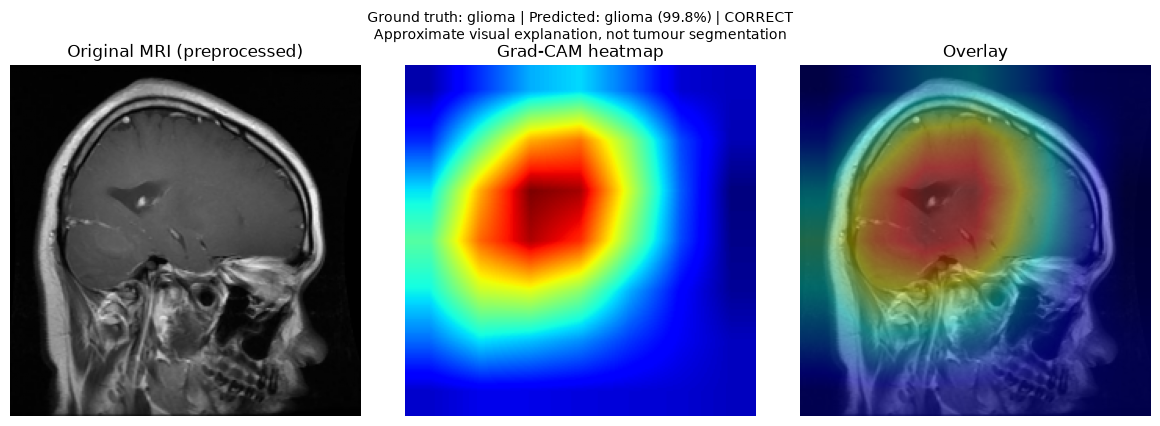

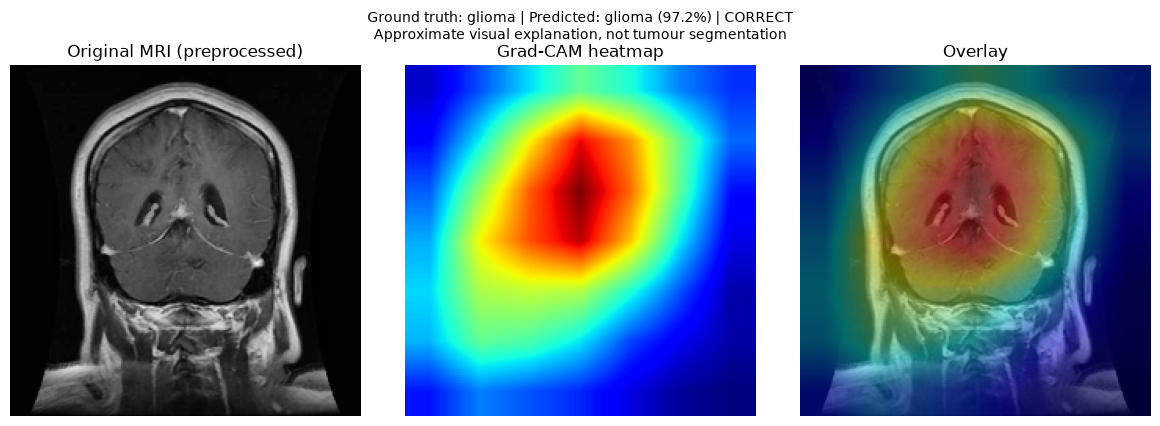

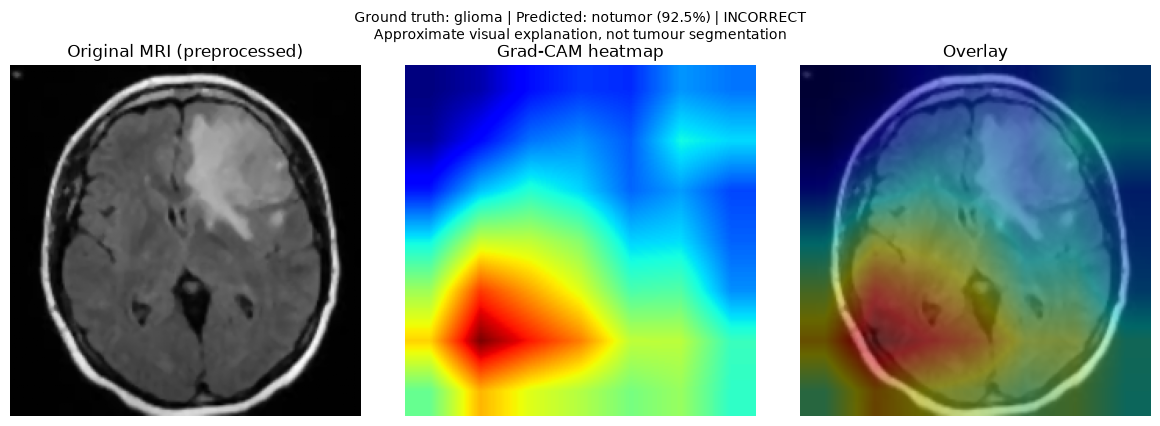

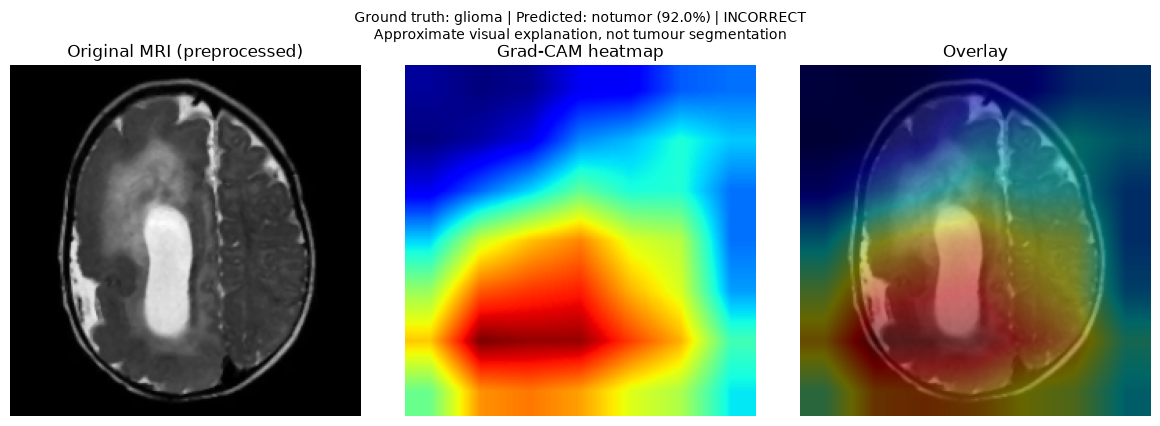

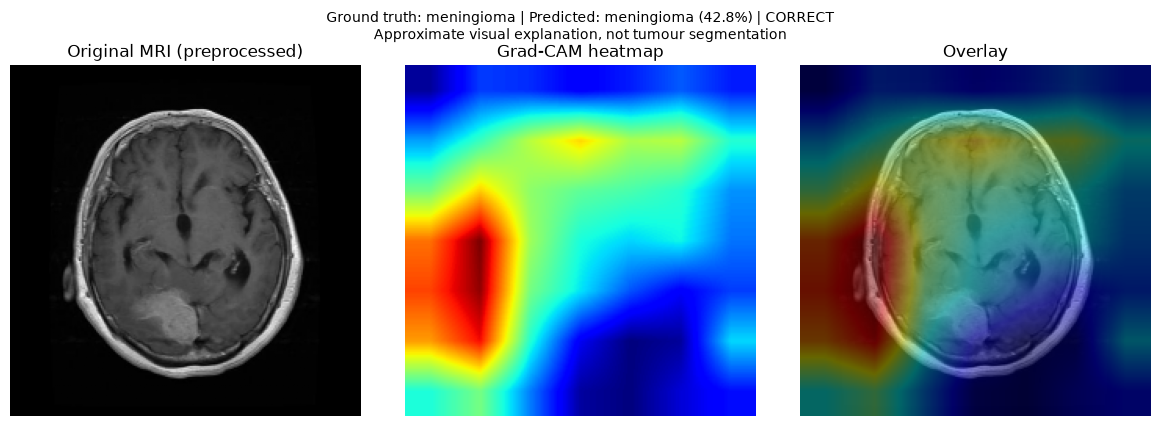

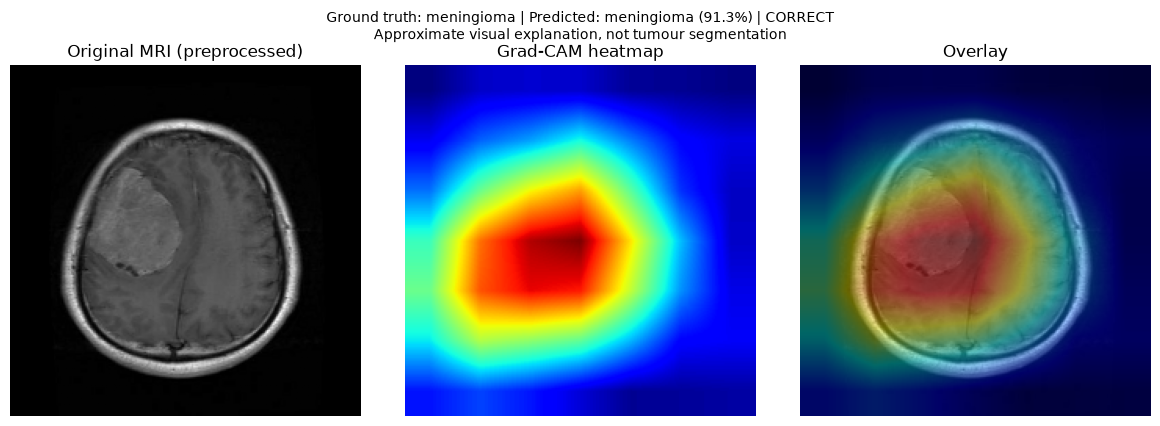

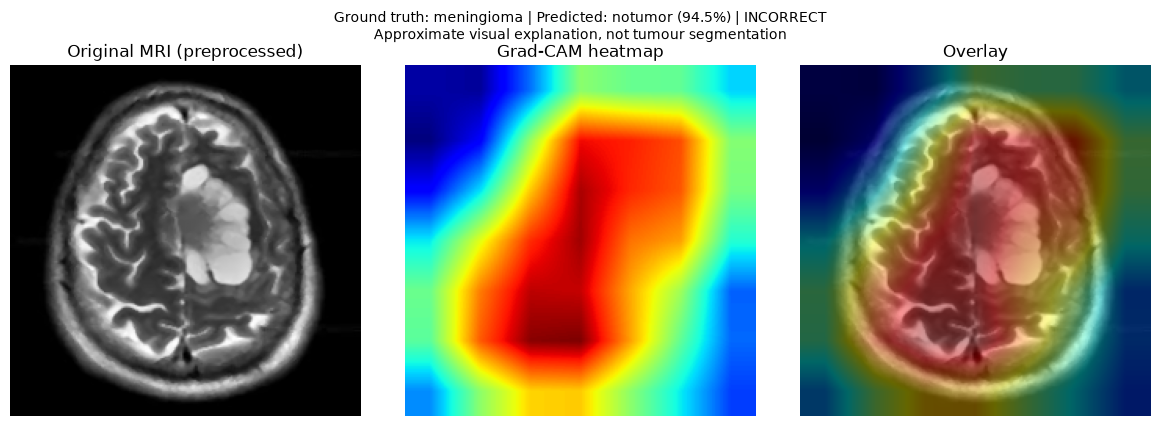

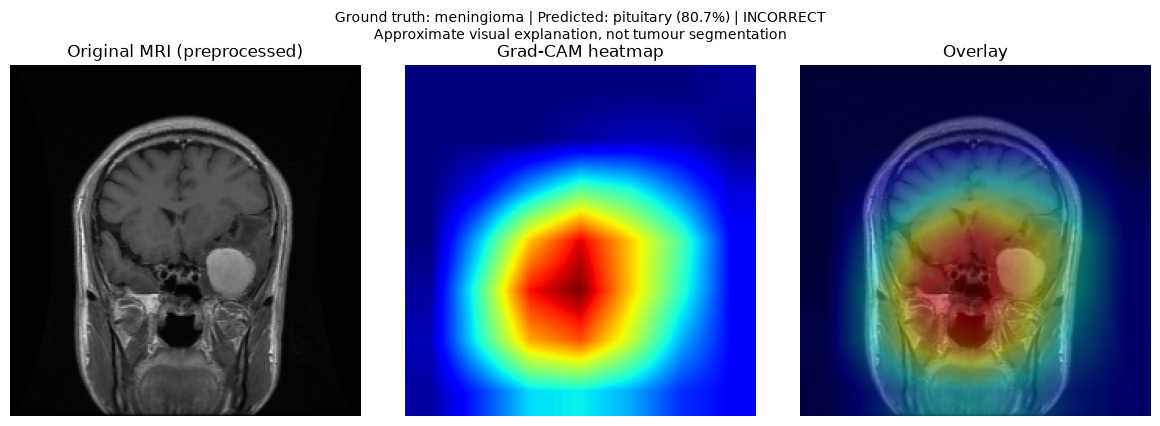

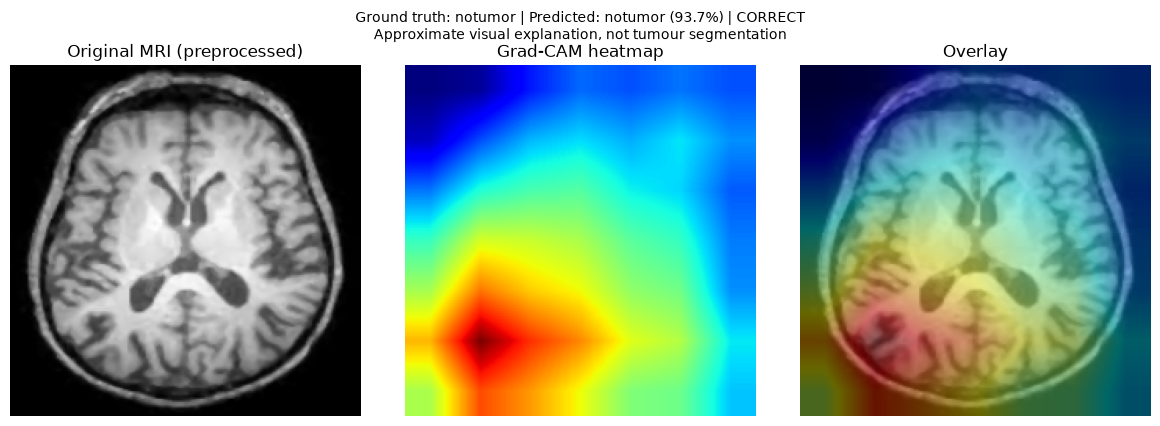

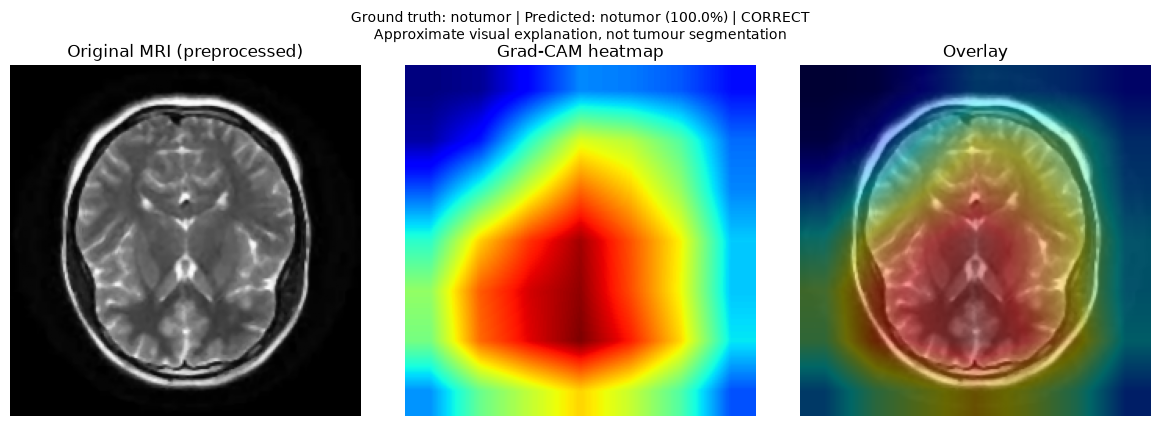

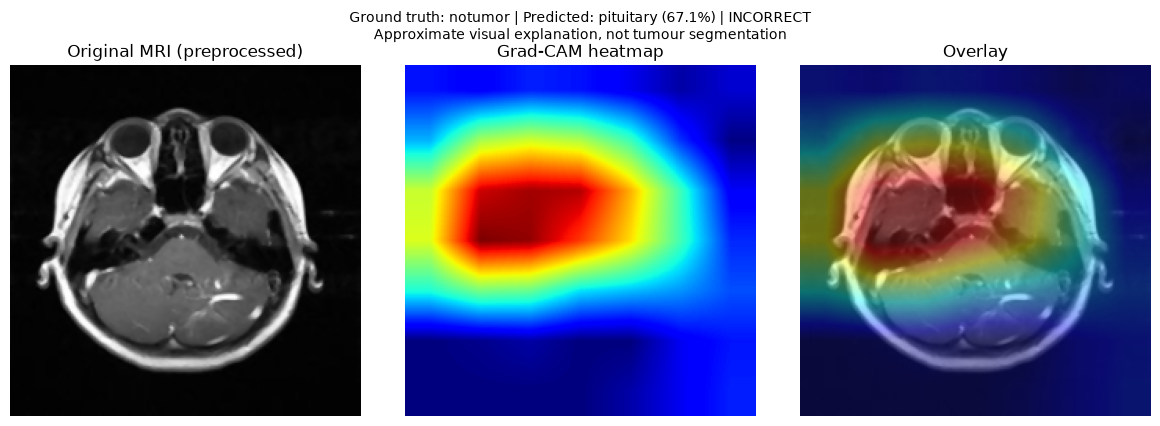

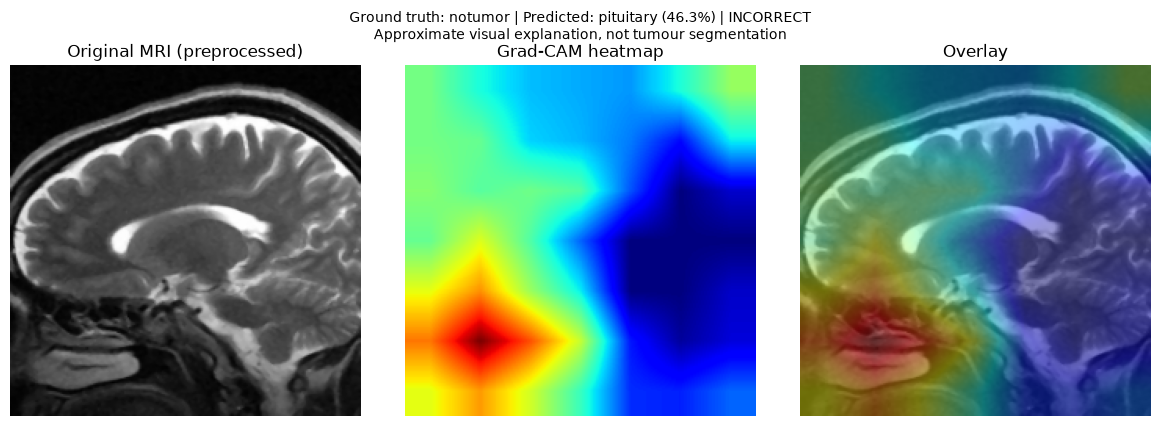

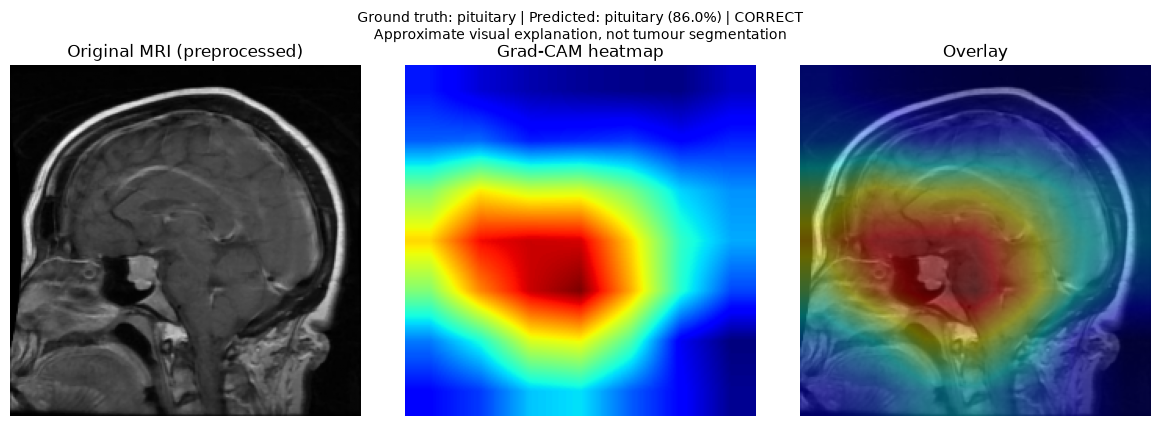

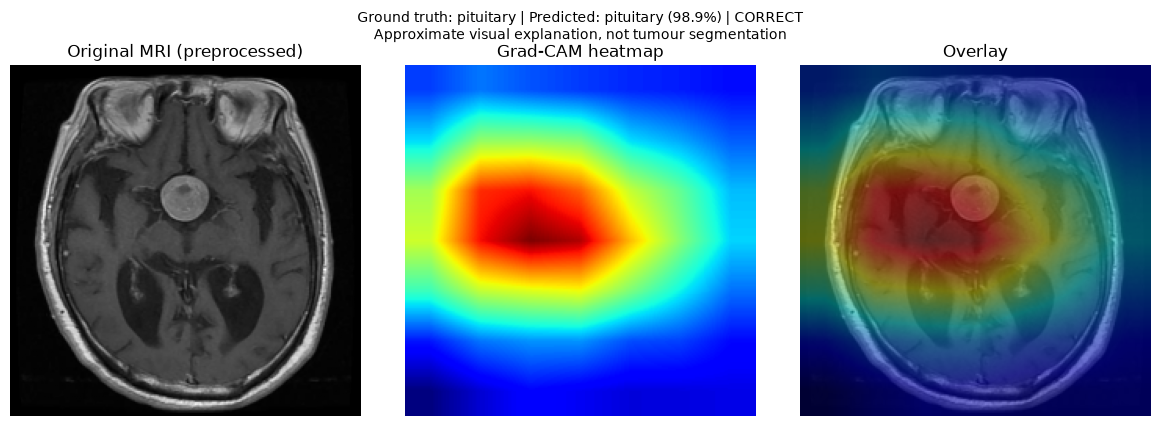

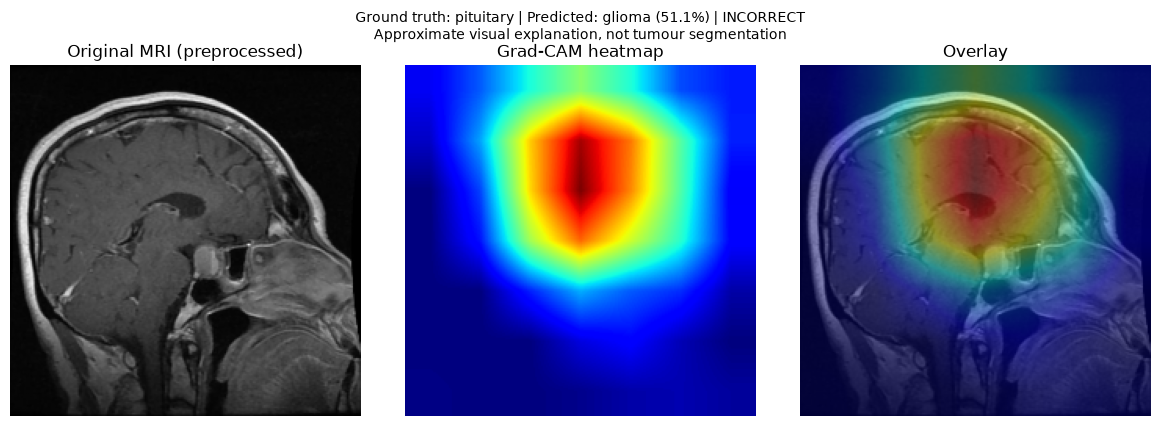

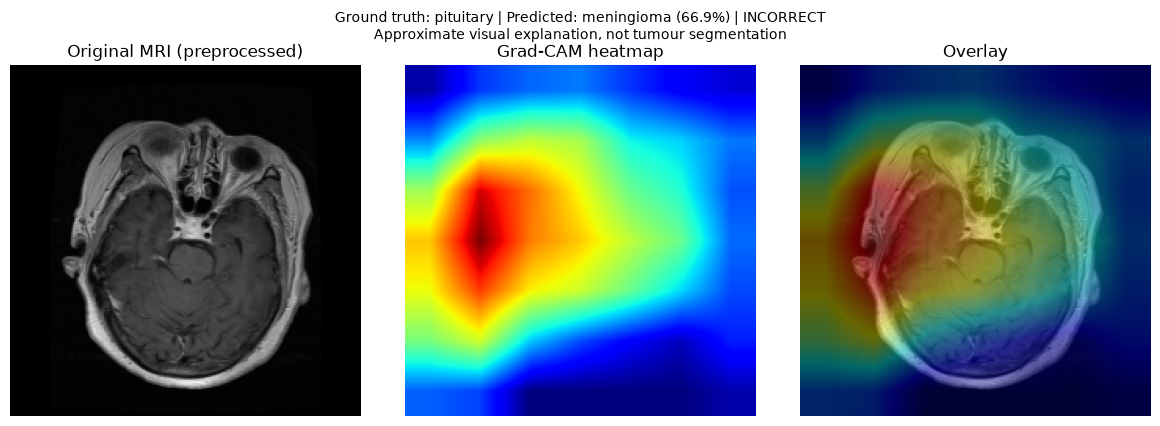

Grad-CAM examples saved under C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project\outputs\gradcam


In [27]:
N_PER_GROUP = 2
best_model = trained[best_mode]["model"]
best_model.eval()

preds_saved = pd.read_csv(preds_path)
examples = []
for cls in rg.CLASS_NAMES:
    for is_correct in [True, False]:
        sub = preds_saved[(preds_saved["label"] == cls) & (preds_saved["correct"] == is_correct)]
        if sub.empty:
            print(f"No {'correct' if is_correct else 'incorrect'} predictions for '{cls}'.")
            continue
        for i in sub.sample(min(N_PER_GROUP, len(sub)), random_state=SEED).index:
            examples.append((i, cls, is_correct))

for i, cls, is_correct in examples:
    row = test_df[test_df["filename"] == preds_saved.loc[i, "filename"]].iloc[0]
    gray, _ = rg.preprocess_gray(row["path"], best_mode, THRESHOLDS)
    cam, pred, probs = rg.explain_image(best_model, gray, DEVICE)
    overlay = rg.overlay_cam(gray, cam)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
    axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Original MRI (preprocessed)")
    axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM heatmap")
    axes[2].imshow(overlay); axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"Ground truth: {cls} | Predicted: {rg.IDX_TO_CLASS[pred]} "
                 f"({probs[pred]:.1%}) | {'CORRECT' if is_correct else 'INCORRECT'}\n"
                 "Approximate visual explanation, not tumour segmentation", fontsize=10)
    plt.tight_layout()
    sub_dir = GRADCAM_DIR / ("correct" if is_correct else "incorrect")
    sub_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(sub_dir / f"{cls}_{Path(row['filename'].replace(chr(92), '/')).stem}.png", dpi=130)
    plt.show()

print("Grad-CAM examples saved under", GRADCAM_DIR)

## 9. Results summary

Reference: `outputs/resnet34/three_experiment_comparison.csv` (test results shown above).
Final numbers come from the run you execute. Do not copy numbers from other studies into this comparison.

In [28]:
display(comparison.round(4))
print("Selected checkpoint:", MODEL_PATH)

,preprocessing,best_epoch,val_accuracy,val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
0,baseline,1,0.8727,0.8647,0.8066,0.8217,0.8064,0.7923,0.7924
1,fixed,1,0.8501,0.8421,0.7822,0.7996,0.7820,0.7621,0.7623
2,adaptive,1,0.8859,0.8835,0.8023,0.8171,0.8020,0.7902,0.7902


Selected checkpoint: C:\Users\Usar\OneDrive\Desktop\projects\Brain_Tumour_Project\models\resnet34_brain_tumor_best.pth


---
## LIVE DEMONSTRATION (evaluation day)

**Restart the kernel and run only this cell.** It loads the saved checkpoint, applies the checkpoint's own
preprocessing, predicts one of four classes, and shows the MRI, the Grad-CAM heatmap and the overlay.
It does not train anything.

Edit `IMAGE_PATH` below. Forward slashes or raw strings both work on Windows.

Loaded checkpoint: resnet34_brain_tumor_best.pth | preprocessing: adaptive | device: cpu
Adaptive / fixed operations applied: ['Median filtering']
Predicted class : notumor
Confidence      : 95.4%
Ground truth    : glioma (split: test)
Class probabilities:
  glioma      0.0346
  meningioma  0.0077
  notumor     0.9541
  pituitary   0.0036


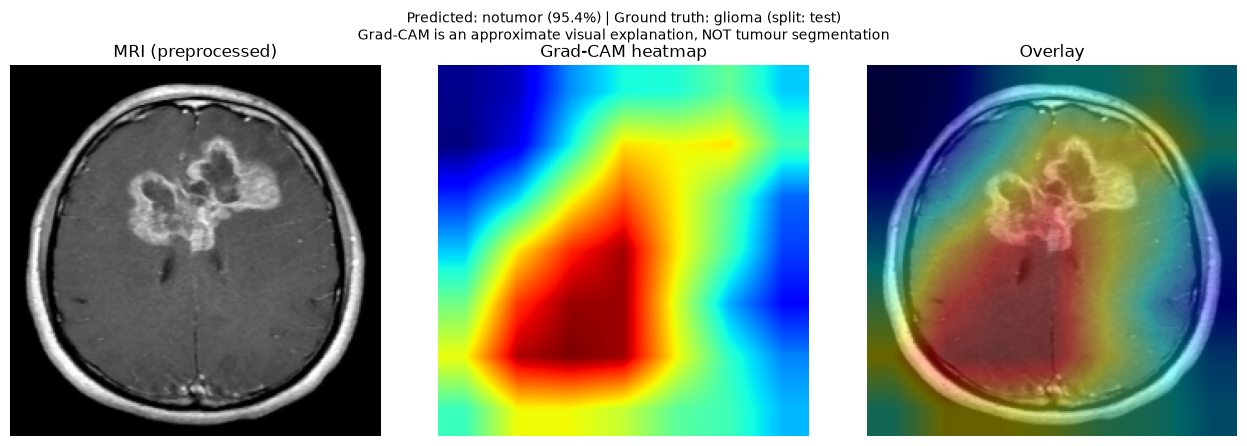

In [29]:
# ======================= LIVE DEMONSTRATION =======================
# Edit this path, then run the cell. Nothing else needs changing.
IMAGE_PATH = r"datasets/Testing/glioma/Te-gl_1.jpg"
CHECKPOINT = "models/resnet34_brain_tumor_best.pth"   # relative to the project root
# ==================================================================

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch


def _project_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / "common" / "resnet_gradcam.py").exists():
            return p
    raise FileNotFoundError("Could not find the project folder (the one containing common/). "
                            "Open the notebook from inside Brain_Tumour_Project.")


ROOT = _project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from common import resnet_gradcam as rg

demo = None
try:
    ckpt_path = ROOT / CHECKPOINT
    if not ckpt_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {ckpt_path}. Run training (sections 4-6) first.")

    img_path = Path(str(IMAGE_PATH).strip().strip('"').strip("'"))
    if not img_path.is_absolute():
        img_path = (ROOT / img_path)
    if not img_path.is_file():
        raise FileNotFoundError(f"IMAGE_PATH is not an existing file: {img_path}")

    device = rg.get_device()
    model, ckpt = rg.load_checkpoint(ckpt_path, device)
    demo = rg.predict_single(model, ckpt, img_path, device)
    print(f"Loaded checkpoint: {ckpt_path.name} | preprocessing: {demo['mode']} | device: {device}")
    if demo["ops"]:
        print("Adaptive / fixed operations applied:", demo["ops"])
except FileNotFoundError as err:
    print("ERROR (file):", err)
except RuntimeError as err:
    print("ERROR (model or image could not be processed):", err)
except Exception as err:  # keep the notebook alive and say what went wrong
    print(f"ERROR ({type(err).__name__}):", err)

if demo is not None:
    # Ground truth lookup from shared/split.csv (matched by file name).
    split_df = pd.read_csv(ROOT / "shared" / "split.csv")
    name = img_path.name
    matches = split_df[split_df["filename"].str.replace("\\", "/", regex=False).str.split("/").str[-1] == name]
    if len(matches) == 1:
        gt_text = f"{matches.iloc[0]['label']} (split: {matches.iloc[0]['split']})"
    elif len(matches) > 1:
        gt_text = "ambiguous: " + ", ".join(matches["filename"].tolist())
    else:
        gt_text = "not in shared/split.csv (ground truth unknown)"

    print(f"Predicted class : {demo['pred_label']}")
    print(f"Confidence      : {demo['confidence']:.1%}")
    print(f"Ground truth    : {gt_text}")
    print("Class probabilities:")
    for name_, p_ in zip(rg.CLASS_NAMES, demo["probs"]):
        print(f"  {name_:<11} {p_:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    axes[0].imshow(demo["gray"], cmap="gray"); axes[0].set_title("MRI (preprocessed)")
    axes[1].imshow(demo["cam"], cmap="jet"); axes[1].set_title("Grad-CAM heatmap")
    axes[2].imshow(demo["overlay"]); axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"Predicted: {demo['pred_label']} ({demo['confidence']:.1%}) | "
                 f"Ground truth: {gt_text}\n"
                 "Grad-CAM is an approximate visual explanation, NOT tumour segmentation",
                 fontsize=10)
    plt.tight_layout()
    plt.show()